In [1]:
import glob
import json
import pandas as pd

# Locate all audio history files
file_paths = glob.glob(
    "Spotify Extended Streaming History/Streaming_History_Audio_*.json"
)

# Merge records across all years
records = []
for file in sorted(file_paths):
  with open(file, "r", encoding="utf-8") as f:
    records.extend(json.load(f))

df = pd.DataFrame(records)
print(f"Total streams loaded: {len(df):,}")

Total streams loaded: 45,797


In [2]:
# 1. Convert timestamps from text to actual datetime objects
df['ts'] = pd.to_datetime(df['ts'])

# 2. Extract specific time components for habit analysis
df['year'] = df['ts'].dt.year
df['month'] = df['ts'].dt.month
df['day_name'] = df['ts'].dt.day_name()
df['hour'] = df['ts'].dt.hour

# 3. Convert milliseconds to a readable format (minutes)
df['minutes_played'] = df['ms_played'] / 60000

# 4. Filter out skipped songs (tracks played for less than 30 seconds)
df_clean = df[df['ms_played'] >= 30000].copy()

# Check the results and the new row count
print(f"Streams after removing skips: {len(df_clean):,}")
df_clean[['ts', 'master_metadata_album_artist_name', 'master_metadata_track_name', 'minutes_played']].head()

Streams after removing skips: 25,926


,ts,master_metadata_album_artist_name,master_metadata_track_name,minutes_played
0,2021-04-03 04:48:13+00:00,Shayne Orok,Fuyu No Hanashi (Given),1.155183
2,2021-04-04 08:56:30+00:00,Anuv Jain,Alag Aasmaan,0.670800
3,2021-04-04 09:00:11+00:00,Anuv Jain,Alag Aasmaan,3.605483
4,2021-04-04 09:05:19+00:00,Anuv Jain,Riha,4.788717
6,2021-04-04 09:09:16+00:00,Anuv Jain,Ocean,3.744833


🏆 Top 10 Artists (Minutes Played):
master_metadata_album_artist_name
Nayyara Noor      6675.2
Pritam            1670.3
Lana Del Rey      1599.9
A.R. Rahman       1562.6
Atif Aslam        1150.4
Ali Sethi         1036.8
Ali Zafar          956.4
BTS                940.3
Aditya Rikhari     841.0
Billie Eilish      792.4
Name: minutes_played, dtype: float64
----------------------------------------

🎵 Top 10 Tracks (Minutes Played):
master_metadata_track_name    master_metadata_album_artist_name
Yeh Dhoop Kinara              Nayyara Noor                         1257.0
Aaj Bazar Mein                Nayyara Noor                          859.4
Tum Mere Pas Raho             Nayyara Noor                          796.0
Dil Ki Khair                  Ali Sethi                             587.3
Person that shares happiness  Sunflower                             564.3
Ae Ishq Hamen Barbad          Nayyara Noor                          562.8
M.                            Anıl Emre Daldal              

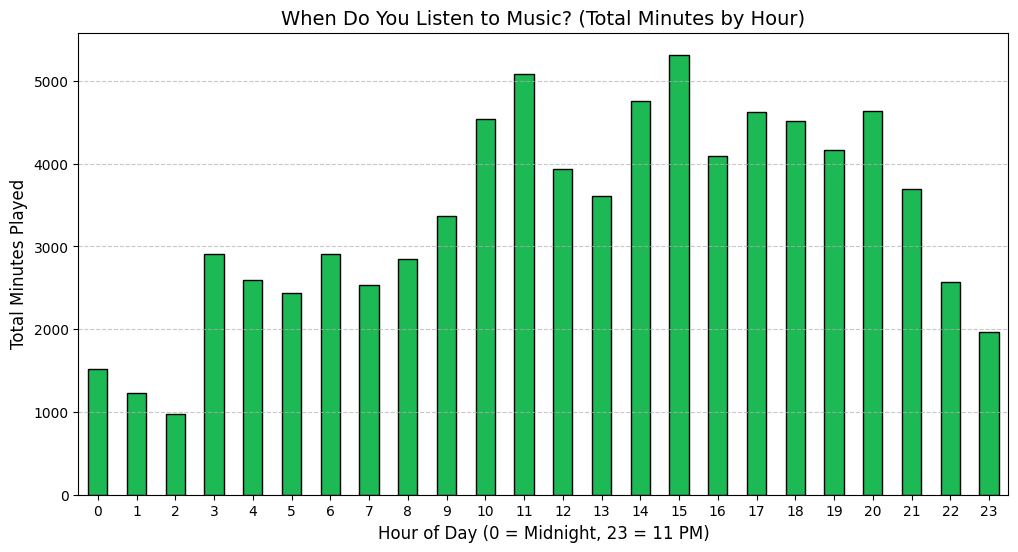

In [3]:
import matplotlib.pyplot as plt

# 1. Top 10 Artists by Total Minutes Played
top_artists = df_clean.groupby('master_metadata_album_artist_name')['minutes_played'].sum().sort_values(ascending=False).head(10)
print("🏆 Top 10 Artists (Minutes Played):")
print(top_artists.round(1))
print("-" * 40)

# 2. Top 10 Tracks by Total Minutes Played
top_tracks = df_clean.groupby(['master_metadata_track_name', 'master_metadata_album_artist_name'])['minutes_played'].sum().sort_values(ascending=False).head(10)
print("\n🎵 Top 10 Tracks (Minutes Played):")
print(top_tracks.round(1))

# 3. Visualizing Listening Habits by Hour of the Day
hourly_listening = df_clean.groupby('hour')['minutes_played'].sum()

plt.figure(figsize=(12, 6))
# Using Spotify's signature green color
hourly_listening.plot(kind='bar', color='#1DB954', edgecolor='black') 
plt.title('When Do You Listen to Music? (Total Minutes by Hour)', fontsize=14)
plt.xlabel('Hour of Day (0 = Midnight, 23 = 11 PM)', fontsize=12)
plt.ylabel('Total Minutes Played', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

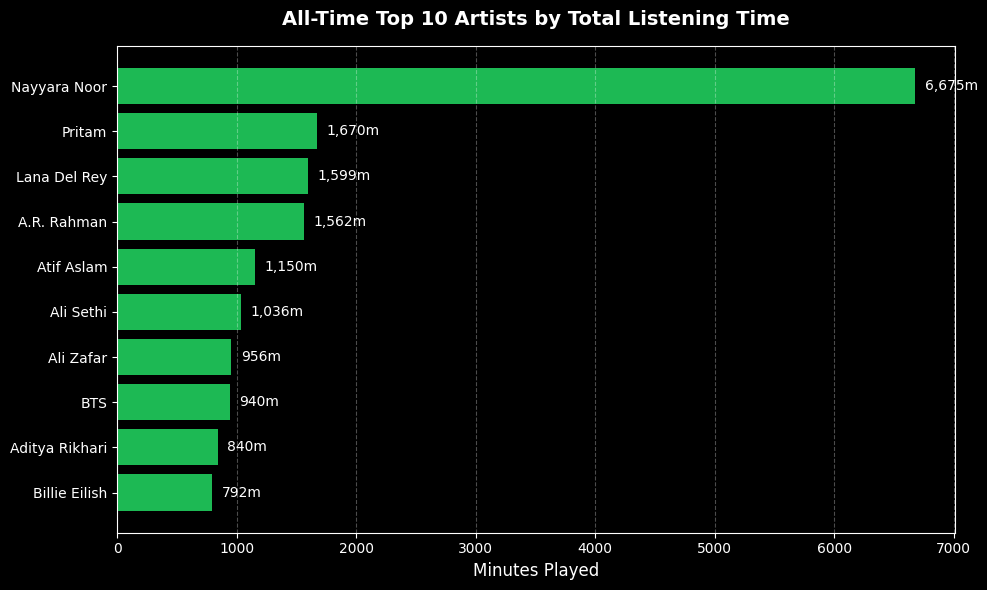

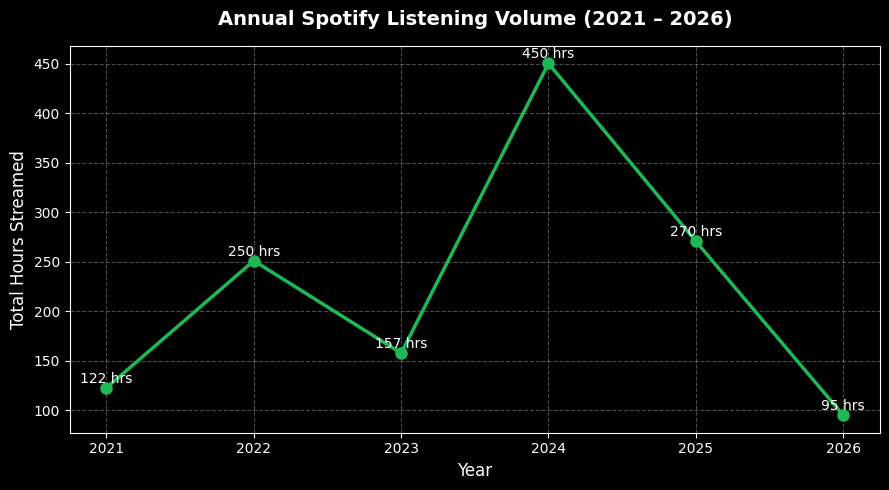

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a dark theme aesthetic matching Spotify's UI
plt.style.use('dark_background')

# --- PLOT 1: Top 10 Artists ---
top_artists_df = (
    df_clean.groupby('master_metadata_album_artist_name')['minutes_played']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_artists_df['master_metadata_album_artist_name'][::-1],
    top_artists_df['minutes_played'][::-1],
    color='#1DB954',
    edgecolor='none',
)

plt.title('All-Time Top 10 Artists by Total Listening Time', fontsize=14, weight='bold', pad=15)
plt.xlabel('Minutes Played', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# Add exact minute labels on the bars
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 80,
      bar.get_y() + bar.get_height() / 2,
      f'{int(width):,}m',
      ha='left',
      va='center',
      fontsize=10,
      color='white',
  )

plt.tight_layout()
plt.savefig('top_10_artists.png', dpi=300)
plt.show()

# --- PLOT 2: Annual Listening Trends ---
yearly_trends = df_clean.groupby('year')['minutes_played'].sum() / 60  # convert to hours

plt.figure(figsize=(9, 5))
plt.plot(yearly_trends.index, yearly_trends.values, marker='o', color='#1DB954', linewidth=2.5, markersize=8)
plt.title('Annual Spotify Listening Volume (2021 – 2026)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Hours Streamed', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)

for x, y in zip(yearly_trends.index, yearly_trends.values):
  plt.text(x, y + 5, f'{int(y):,} hrs', ha='center', fontsize=10, color='white')

plt.tight_layout()
plt.savefig('yearly_trends.png', dpi=300)
plt.show()

In [5]:
# Calculate artist consistency: number of distinct years listened to each artist
artist_loyalty = df_clean.groupby('master_metadata_album_artist_name').agg(
    total_minutes=('minutes_played', 'sum'),
    years_active=('year', 'nunique'),
    first_heard=('year', 'min'),
    last_heard=('year', 'max'),
).reset_index()

# Filter to artists with meaningful listening time (> 300 minutes)
consistent_artists = (
    artist_loyalty[artist_loyalty['total_minutes'] >= 300]
    .sort_values(by=['years_active', 'total_minutes'], ascending=[False, False])
)

print("📅 Long-Term Core Artists (Present Across Multiple Years):")
print(consistent_artists.head(10).to_string(index=False))

📅 Long-Term Core Artists (Present Across Multiple Years):
master_metadata_album_artist_name  total_minutes  years_active  first_heard  last_heard
                           Pritam    1670.270033             6         2021        2026
                     Lana Del Rey    1599.869383             6         2021        2026
                      A.R. Rahman    1562.633950             6         2021        2026
                       Atif Aslam    1150.388200             6         2021        2026
                        Ali Sethi    1036.839050             6         2021        2026
                        Ali Zafar     956.416383             6         2021        2026
                    Billie Eilish     792.413650             6         2021        2026
                       Iqbal Bano     789.160233             6         2021        2026
                     Mehdi Hassan     731.265367             6         2021        2026
                      Andrew Bird     638.391933             6

In [6]:
df_clean.to_csv('spotify_cleaned_history.csv', index=False)